# Trustworthy Analysis of an Email Marketing Experiment

**Question:** A retailer emailed its customers in a randomized experiment. Did the emails work, how sure
can we be, and **who** should get which email next time?

**Data:** Kevin Hillstrom's MineThatData E-Mail Analytics Challenge (2008). 64,000 customers who bought
something in the last 12 months were randomly split into three equal groups:
- **Mens E-Mail**: received an email featuring men's merchandise
- **Womens E-Mail**: received an email featuring women's merchandise
- **No E-Mail**: control group, received nothing

Outcomes were tracked for two weeks: `visit` (visited the website), `conversion` (bought something) and
`spend` (dollars spent).

**What this notebook does, in order:**
1. Checks the experiment can be trusted (sample ratio mismatch, covariate balance)
2. Computes the group metrics in SQL
3. Measures the effects with z-tests and bootstrap confidence intervals
4. Corrects for multiple testing (Holm)
5. Tries CUPED variance reduction, and checks the result against theory
6. Simulates the danger of "peeking" at results early, and implements a sequential-testing fix
7. Finds which customers respond (segments) and builds an uplift model to pick the best 10,000 customers
8. Summarises the recommendation

In [1]:
import json
import sqlite3
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
summary = {}  # key numbers collected along the way, saved at the end

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

## 0. Load the data
The notebook looks for the CSV in `data/hillstrom.csv` (or next to the notebook). If it is not there, it
downloads it from the original MineThatData link.

In [2]:
URL = ("http://www.minethatdata.com/"
       "Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv")
candidates = [Path("data/hillstrom.csv"), Path("hillstrom.csv")]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    path = Path("data/hillstrom.csv"); path.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, path)

df = pd.read_csv(path)
CONTROL, MENS, WOMENS = "No E-Mail", "Mens E-Mail", "Womens E-Mail"
EMAILS = [MENS, WOMENS]
METRICS = ["visit", "conversion", "spend"]

print(df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.head()

(64000, 12)
Missing values: 0


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [3]:
print(df["segment"].value_counts())
print(f"\nShare of customers who spent anything: {(df['spend'] > 0).mean():.2%}")
df.describe().round(2)

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

Share of customers who spent anything: 0.90%


,recency,history,mens,womens,newbie,visit,conversion,spend
count,64000.00,64000.00,64000.00,64000.00,64000.0,64000.00,64000.00,64000.00
mean,5.76,242.09,0.55,0.55,0.5,0.15,0.01,1.05
std,3.51,256.16,0.50,0.50,0.5,0.35,0.09,15.04
min,1.00,29.99,0.00,0.00,0.0,0.00,0.00,0.00
25%,2.00,64.66,0.00,0.00,0.0,0.00,0.00,0.00
50%,6.00,158.11,1.00,1.00,1.0,0.00,0.00,0.00
75%,9.00,325.66,1.00,1.00,1.0,0.00,0.00,0.00
max,12.00,3345.93,1.00,1.00,1.0,1.00,1.00,499.00


**Key observation:** fewer than 1% of customers spent anything, so `spend` is almost all zeros with a few
large values. That shape matters later: it is why we use a bootstrap for spend.

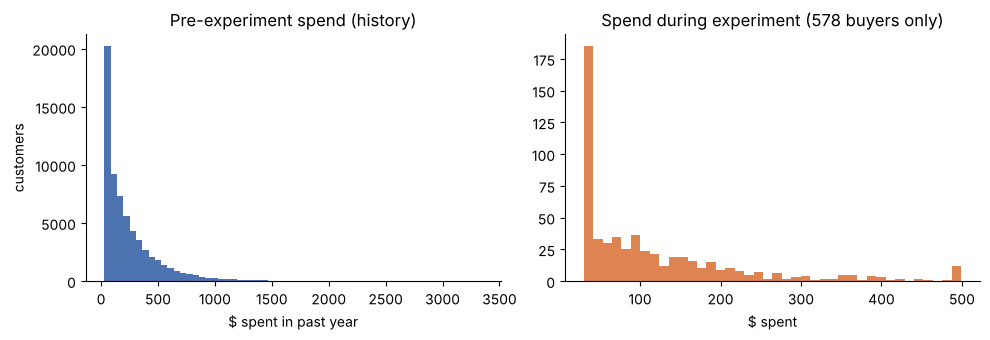

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["history"], bins=60, color="#4C72B0")
axes[0].set(title="Pre-experiment spend (history)", xlabel="$ spent in past year", ylabel="customers")
buyers = df.loc[df["spend"] > 0, "spend"]
axes[1].hist(buyers, bins=40, color="#DD8452")
axes[1].set(title=f"Spend during experiment ({len(buyers)} buyers only)", xlabel="$ spent")
save_fig("01_distributions")

## 1. Can we trust this experiment?
Before measuring any effect, check that the randomization worked. If it did not, every result after this
is suspect.

### 1a. Sample ratio mismatch (SRM)
Each group was meant to get exactly 1/3 of customers. A chi-square goodness-of-fit test asks: are the
observed group sizes plausible if the split really was 1/3 each? A tiny p-value (e.g. < 0.001) would mean
something went wrong (a bug in assignment, data loss in one group, ...), and we should stop and investigate.

In [5]:
observed = df["segment"].value_counts().reindex([CONTROL, MENS, WOMENS])
expected = np.full(3, len(df) / 3)
chi2, p_srm = stats.chisquare(observed, expected)
print(observed.to_string())
print(f"\nExpected per group: {expected[0]:.0f}")
print(f"SRM chi-square = {chi2:.2f}, p-value = {p_srm:.3f}")
print("PASS: group sizes are consistent with a 1/3 split." if p_srm > 0.001
      else "FAIL: sample ratio mismatch, investigate before trusting results!")
summary["srm_p_value"] = round(float(p_srm), 3)

segment
No E-Mail        21306
Mens E-Mail      21307
Womens E-Mail    21387

Expected per group: 21333
SRM chi-square = 0.20, p-value = 0.904
PASS: group sizes are consistent with a 1/3 split.


### 1b. Covariate balance
Everything measured **before** the emails were sent (past spend, recency, channel, ...) should look the
same across groups, because the emails could not have changed it. We check two ways:
- **Standardized mean difference (SMD)**: difference in means divided by the pooled standard deviation.
  A common rule of thumb is |SMD| < 0.1 means "balanced".
- **Statistical tests**: Kruskal-Wallis for numeric columns (robust to skew), chi-square for categorical
  columns. Here we *want* large p-values.

In [6]:
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)

numeric_cols = ["history", "recency", "mens", "womens", "newbie"]
rows = []
for col in numeric_cols:
    groups = [df.loc[df["segment"] == g, col] for g in [CONTROL, MENS, WOMENS]]
    rows.append({
        "covariate": col,
        "mean_control": groups[0].mean(), "mean_mens": groups[1].mean(), "mean_womens": groups[2].mean(),
        "SMD_mens_vs_ctrl": smd(groups[1], groups[0]), "SMD_womens_vs_ctrl": smd(groups[2], groups[0]),
        "p_value (Kruskal-Wallis)": stats.kruskal(*groups).pvalue,
    })
balance = pd.DataFrame(rows).round(4)
print(balance.to_string(index=False))

cat_rows = []
for col in ["zip_code", "channel", "history_segment"]:
    table = pd.crosstab(df[col], df["segment"])
    cat_rows.append({"covariate": col, "p_value (chi-square)": stats.chi2_contingency(table).pvalue})
print()
print(pd.DataFrame(cat_rows).round(4).to_string(index=False))

max_smd = balance[["SMD_mens_vs_ctrl", "SMD_womens_vs_ctrl"]].abs().max().max()
print(f"\nLargest |SMD| = {max_smd:.4f} (rule of thumb: < 0.1 is balanced)")
summary["max_abs_smd"] = round(float(max_smd), 4)

covariate  mean_control  mean_mens  mean_womens  SMD_mens_vs_ctrl  SMD_womens_vs_ctrl  p_value (Kruskal-Wallis)
  history      240.8827   242.8359     242.5366            0.0076              0.0065                    0.6669
  recency        5.7497     5.7736       5.7678            0.0068              0.0052                    0.7941
     mens        0.5532     0.5509       0.5489           -0.0046             -0.0086                    0.6717
   womens        0.5476     0.5514       0.5501            0.0076              0.0049                    0.7289
   newbie        0.5020     0.5015       0.5032           -0.0009              0.0026                    0.9339

      covariate  p_value (chi-square)
       zip_code                0.5795
        channel                0.4580
history_segment                0.3580

Largest |SMD| = 0.0086 (rule of thumb: < 0.1 is balanced)


**Reading it:** all SMDs are far below 0.1. With 8 balance tests, one or two p-values below 0.05 can
happen by pure chance (that is exactly the multiple-testing issue in Section 4), so we look at the overall
picture and the SMD sizes, not a single p-value. Randomization looks healthy, so we can proceed.

## 2. Group metrics in SQL
The same aggregation an analyst would run on a company database. SQLite is built into Python, so no extra
installation is needed. The queries are also saved in `queries.sql`.

In [7]:
con = sqlite3.connect(":memory:")
df.to_sql("customers", con, index=False)

query_group_metrics = """
SELECT segment,
       COUNT(*)                                        AS customers,
       ROUND(AVG(visit) * 100, 2)                      AS visit_rate_pct,
       ROUND(AVG(conversion) * 100, 3)                 AS conversion_rate_pct,
       ROUND(AVG(spend), 3)                            AS spend_per_customer,
       ROUND(SUM(spend), 0)                            AS total_spend,
       ROUND(SUM(spend) / NULLIF(SUM(conversion), 0), 2) AS spend_per_buyer
FROM customers
GROUP BY segment
ORDER BY spend_per_customer DESC;
"""
group_metrics = pd.read_sql(query_group_metrics, con)
group_metrics

,segment,customers,visit_rate_pct,conversion_rate_pct,spend_per_customer,total_spend,spend_per_buyer
0,Mens E-Mail,21307,18.28,1.253,1.423,30312.0,113.53
1,Womens E-Mail,21387,15.14,0.884,1.077,23038.0,121.89
2,No E-Mail,21306,10.62,0.573,0.653,13908.0,114.00


In [8]:
query_by_buyer_type = """
SELECT CASE WHEN mens = 1 AND womens = 1 THEN 'Bought both'
            WHEN mens = 1 THEN 'Bought mens only'
            ELSE 'Bought womens only' END             AS buyer_type,
       segment,
       COUNT(*)                                        AS customers,
       ROUND(AVG(visit) * 100, 2)                      AS visit_rate_pct
FROM customers
GROUP BY buyer_type, segment
ORDER BY buyer_type, segment;
"""
pd.read_sql(query_by_buyer_type, con).pivot(index="buyer_type", columns="segment", values="visit_rate_pct")

segment,Mens E-Mail,No E-Mail,Womens E-Mail
buyer_type,,,
Bought both,31.50,18.05,25.17
Bought mens only,16.90,9.98,11.09
Bought womens only,16.64,9.58,16.98


## 3. Measuring the effects
For each email vs the control group:
- **visit** and **conversion** are yes/no outcomes, so we use a **two-proportion z-test**, with a 95%
  confidence interval (CI) for the difference in rates.
- **spend** is very skewed (mostly zeros), so instead of relying only on a formula we use a
  **bootstrap**: resample customers with replacement 5,000 times, recompute the difference in average spend
  each time, and take the middle 95% of those differences as the CI. We also report Welch's t-test p-value.

**What a p-value means:** if the email truly had *no* effect, how often would we see a difference at least
this large just by random chance? It is *not* the probability that the email works.

In [9]:
def two_prop_ztest(x_t, n_t, x_c, n_c, alpha=0.05):
    """Two-proportion z-test. Pooled SE for the p-value, unpooled SE for the CI."""
    p_t, p_c = x_t / n_t, x_c / n_c
    p_pool = (x_t + x_c) / (n_t + n_c)
    z = (p_t - p_c) / np.sqrt(p_pool * (1 - p_pool) * (1 / n_t + 1 / n_c))
    se = np.sqrt(p_t * (1 - p_t) / n_t + p_c * (1 - p_c) / n_c)
    zc = stats.norm.ppf(1 - alpha / 2)
    diff = p_t - p_c
    return {"control": p_c, "treatment": p_t, "diff": diff, "ci_low": diff - zc * se,
            "ci_high": diff + zc * se, "p_value": 2 * stats.norm.sf(abs(z))}


def bootstrap_diff_in_means(y_t, y_c, n_boot=5000, seed=SEED, chunk=250):
    """Distribution of mean(y_t) - mean(y_c) under resampling with replacement."""
    r = np.random.default_rng(seed)
    out = np.empty(n_boot)
    for start in range(0, n_boot, chunk):
        m = min(chunk, n_boot - start)
        it = r.integers(0, len(y_t), size=(m, len(y_t)))
        ic = r.integers(0, len(y_c), size=(m, len(y_c)))
        out[start:start + m] = y_t[it].mean(axis=1) - y_c[ic].mean(axis=1)
    return out


ctrl = df[df["segment"] == CONTROL]
results, boot_dists = [], {}
for email in EMAILS:
    trt = df[df["segment"] == email]
    for metric in ["visit", "conversion"]:
        r = two_prop_ztest(trt[metric].sum(), len(trt), ctrl[metric].sum(), len(ctrl))
        results.append({"email": email, "metric": metric, **r})
    y_t, y_c = trt["spend"].to_numpy(), ctrl["spend"].to_numpy()
    boot = bootstrap_diff_in_means(y_t, y_c)
    boot_dists[email] = boot
    results.append({"email": email, "metric": "spend", "control": y_c.mean(), "treatment": y_t.mean(),
                    "diff": y_t.mean() - y_c.mean(), "ci_low": np.percentile(boot, 2.5),
                    "ci_high": np.percentile(boot, 97.5),
                    "p_value": stats.ttest_ind(y_t, y_c, equal_var=False).pvalue})

effects = pd.DataFrame(results)
effects["relative_lift_pct"] = 100 * effects["diff"] / effects["control"]
effects.round(4)

,email,metric,control,treatment,diff,ci_low,ci_high,p_value,relative_lift_pct
0,Mens E-Mail,visit,0.1062,0.1828,0.0766,0.0700,0.0832,0.0000,72.1405
1,Mens E-Mail,conversion,0.0057,0.0125,0.0068,0.0050,0.0086,0.0000,118.8422
2,Mens E-Mail,spend,0.6528,1.4226,0.7698,0.4856,1.0630,0.0000,117.9289
3,Womens E-Mail,visit,0.1062,0.1514,0.0452,0.0389,0.0516,0.0000,42.6055
4,Womens E-Mail,conversion,0.0057,0.0088,0.0031,0.0015,0.0047,0.0002,54.3313
5,Womens E-Mail,spend,0.6528,1.0772,0.4244,0.1607,0.6783,0.0011,65.0152


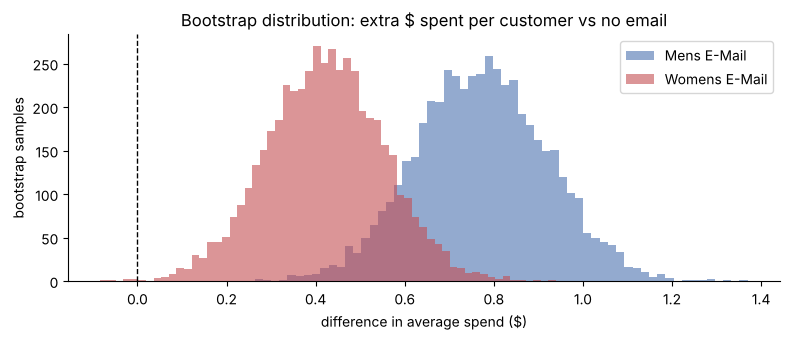

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for email, color in zip(EMAILS, ["#4C72B0", "#C44E52"]):
    ax.hist(boot_dists[email], bins=60, alpha=0.6, color=color, label=email)
ax.axvline(0, color="black", lw=1, ls="--")
ax.set(title="Bootstrap distribution: extra $ spent per customer vs no email",
       xlabel="difference in average spend ($)", ylabel="bootstrap samples")
ax.legend()
save_fig("02_bootstrap_spend")

**Reading it:** both bootstrap distributions sit clearly above 0, so both emails increased spend, and the
Mens E-Mail by more.
The bootstrap CI and Welch's t-test agree here because the groups are large (21,000+ customers each), so the
central limit theorem kicks in even for this skewed metric. The bootstrap is the safer default when you are
not sure.

## 4. Multiple testing correction (Holm)
We ran 6 tests (2 emails x 3 metrics). At a 5% significance level, the chance of **at least one** false
positive across 6 independent tests of nothing is 1 - 0.95^6 = about 26%, not 5%.

The **Holm correction** controls this "family-wise error rate" at 5%. It sorts the p-values from smallest
to largest and multiplies the smallest by 6, the next by 5, and so on (keeping the adjusted values in
order). It is never worse than the simpler Bonferroni correction (multiply all by 6).

In [11]:
def holm_adjust(pvals):
    p = np.asarray(pvals, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adjusted = np.empty(m)
    running_max = 0.0
    for rank, idx in enumerate(order):
        running_max = max(running_max, min(1.0, (m - rank) * p[idx]))
        adjusted[idx] = running_max
    return adjusted

print(f"Chance of >= 1 false positive in 6 tests without correction: {1 - 0.95 ** 6:.1%}")
effects["p_holm"] = holm_adjust(effects["p_value"])
effects["significant_after_holm"] = effects["p_holm"] < 0.05
effects_display = effects[["email", "metric", "control", "treatment", "diff", "ci_low", "ci_high",
                           "relative_lift_pct", "p_value", "p_holm", "significant_after_holm"]]
effects_display.round(5)

Chance of >= 1 false positive in 6 tests without correction: 26.5%


,email,metric,control,treatment,diff,ci_low,ci_high,relative_lift_pct,p_value,p_holm,significant_after_holm
0,Mens E-Mail,visit,0.10617,0.18276,0.07659,0.06995,0.08323,72.14046,0.00000,0.00000,True
1,Mens E-Mail,conversion,0.00573,0.01253,0.00681,0.00500,0.00861,118.84219,0.00000,0.00000,True
2,Mens E-Mail,spend,0.65279,1.42262,0.76983,0.48560,1.06299,117.92888,0.00000,0.00000,True
3,Womens E-Mail,visit,0.10617,0.15140,0.04523,0.03889,0.05157,42.60551,0.00000,0.00000,True
4,Womens E-Mail,conversion,0.00573,0.00884,0.00311,0.00150,0.00472,54.33130,0.00016,0.00031,True
5,Womens E-Mail,spend,0.65279,1.07720,0.42441,0.16072,0.67828,65.01519,0.00113,0.00113,True


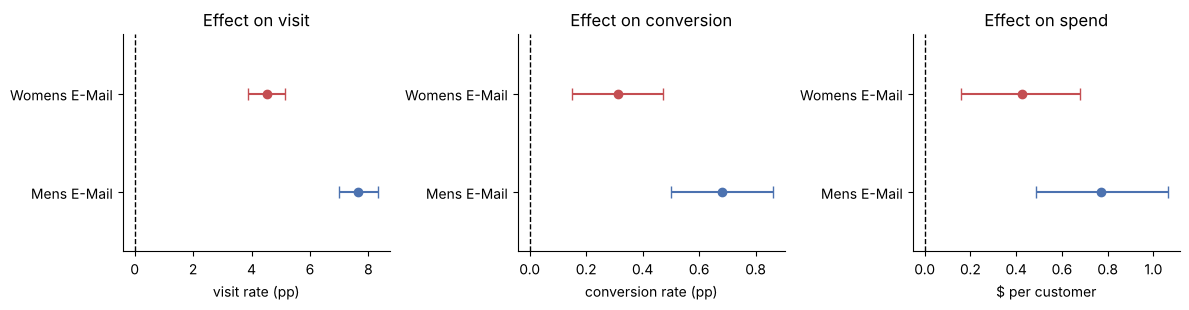

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
labels = {"visit": "visit rate (pp)", "conversion": "conversion rate (pp)", "spend": "$ per customer"}
for ax, metric in zip(axes, METRICS):
    sub = effects[effects["metric"] == metric].reset_index(drop=True)
    scale = 100 if metric != "spend" else 1
    for i, row in sub.iterrows():
        ax.errorbar(row["diff"] * scale, i, xerr=[[(row["diff"] - row["ci_low"]) * scale],
                    [(row["ci_high"] - row["diff"]) * scale]], fmt="o", capsize=4,
                    color=["#4C72B0", "#C44E52"][i])
    ax.axvline(0, color="black", lw=1, ls="--")
    ax.set_yticks(range(len(sub)), sub["email"]); ax.set_ylim(-0.6, len(sub) - 0.4)
    ax.set(title=f"Effect on {metric}", xlabel=labels[metric])
save_fig("03_effects_forest")

for email in EMAILS:
    for metric in METRICS:
        row = effects[(effects.email == email) & (effects.metric == metric)].iloc[0]
        summary[f"{email}|{metric}"] = {k: float(row[k]) for k in
                                         ["control", "treatment", "diff", "ci_low", "ci_high",
                                          "relative_lift_pct", "p_value", "p_holm"]}

## 5. CUPED: can past behaviour reduce the noise?
**Idea (from Microsoft's Bing experimentation team, Deng et al., 2013):** part of the variation in
outcomes comes from who the customer already is. Big past spenders tend to visit more anyway. If we
subtract the part of each customer's outcome that is predictable from data collected *before* the
experiment, the remaining metric is less noisy, so confidence intervals get narrower.

For one covariate X (here `history`, past-year spend):

$$Y_{cuped} = Y - \theta\,(X - \bar X), \qquad \theta = \frac{\mathrm{Cov}(X, Y)}{\mathrm{Var}(X)}$$

Because X was measured before randomization, it is unrelated to which email someone got, so the
**average effect stays unbiased**; only the noise drops. Theory says the variance falls by a factor of
(1 - rho^2), where rho is the correlation between X and Y.

We also try a multi-covariate version (regression adjustment) using all pre-experiment columns.

In [13]:
def cuped_single(y, x):
    theta = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
    return y - theta * (x - x.mean()), theta


def cuped_multi(y, X):
    Xc = X - X.mean(axis=0)
    beta, *_ = np.linalg.lstsq(Xc, y - y.mean(), rcond=None)
    return y - Xc @ beta


def mean_diff_ci(y, groups, email, alpha=0.05):
    a, b = y[groups == email], y[groups == CONTROL]
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    zc = stats.norm.ppf(1 - alpha / 2)
    return diff, diff - zc * se, diff + zc * se


pre_cols = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]
X_pre = pd.get_dummies(df[pre_cols], drop_first=True).astype(float).to_numpy()
seg_arr = df["segment"].to_numpy()

cuped_rows = []
for metric in METRICS:
    y = df[metric].to_numpy(dtype=float)
    y_single, theta = cuped_single(y, df["history"].to_numpy(dtype=float))
    y_multi = cuped_multi(y, X_pre)
    rho = np.corrcoef(df["history"], y)[0, 1]
    for email in EMAILS:
        d0, l0, h0 = mean_diff_ci(y, seg_arr, email)
        d1, l1, h1 = mean_diff_ci(y_single, seg_arr, email)
        d2, l2, h2 = mean_diff_ci(y_multi, seg_arr, email)
        cuped_rows.append({
            "metric": metric, "email": email,
            "effect_raw": d0, "effect_cuped": d1, "effect_multi": d2,
            "ci_width_raw": h0 - l0, "ci_width_cuped": h1 - l1, "ci_width_multi": h2 - l2,
            "var_reduction_cuped_pct": 100 * (1 - y_single.var() / y.var()),
            "theory_rho_sq_pct": 100 * rho ** 2,
            "var_reduction_multi_pct": 100 * (1 - y_multi.var() / y.var()),
        })
cuped_table = pd.DataFrame(cuped_rows)
cuped_table["ci_narrower_multi_pct"] = 100 * (1 - cuped_table["ci_width_multi"] / cuped_table["ci_width_raw"])
cuped_table.round(5)

,metric,email,effect_raw,effect_cuped,effect_multi,ci_width_raw,ci_width_cuped,ci_width_multi,var_reduction_cuped_pct,theory_rho_sq_pct,var_reduction_multi_pct,ci_narrower_multi_pct
0,visit,Mens E-Mail,0.07659,0.07641,0.07601,0.01327,0.01324,0.01308,0.42450,0.42450,2.66880,1.42717
1,visit,Womens E-Mail,0.04523,0.04508,0.04548,0.01268,0.01265,0.01252,0.42450,0.42450,2.66880,1.28444
2,conversion,Mens E-Mail,0.00681,0.00678,0.00677,0.00361,0.00361,0.00361,0.08646,0.08646,0.19199,0.10637
3,conversion,Womens E-Mail,0.00311,0.00309,0.00312,0.00322,0.00322,0.00322,0.08646,0.08646,0.19199,0.08221
4,spend,Mens E-Mail,0.76983,0.76734,0.76635,0.56936,0.56923,0.56903,0.04721,0.04721,0.09293,0.05811
5,spend,Womens E-Mail,0.42441,0.42230,0.42575,0.51090,0.51080,0.51073,0.04721,0.04721,0.09293,0.03270


In [14]:
best = cuped_table.sort_values("var_reduction_multi_pct", ascending=False).iloc[0]
print(f"Single-covariate CUPED (history) variance reduction: "
      f"{cuped_table['var_reduction_cuped_pct'].min():.2f}% to {cuped_table['var_reduction_cuped_pct'].max():.2f}%")
print("  ...matches theory (rho^2) almost exactly:",
      cuped_table[["metric", "var_reduction_cuped_pct", "theory_rho_sq_pct"]]
      .drop_duplicates("metric").round(3).to_dict("records"))
print(f"Best multi-covariate result: '{best['metric']}', variance down {best['var_reduction_multi_pct']:.1f}%, "
      f"CI {best['ci_narrower_multi_pct']:.1f}% narrower "
      f"(= about {best['var_reduction_multi_pct']:.1f}% fewer customers needed for the same precision)")
print("Effect estimates barely move (unbiased), only the CI width changes.")
summary["cuped_var_reduction_visit_multi_pct"] = round(float(
    cuped_table.loc[cuped_table.metric == "visit", "var_reduction_multi_pct"].iloc[0]), 2)
summary["cuped_var_reduction_spend_history_pct"] = round(float(
    cuped_table.loc[cuped_table.metric == "spend", "var_reduction_cuped_pct"].iloc[0]), 3)
summary["corr_history_spend"] = round(float(np.corrcoef(df["history"], df["spend"])[0, 1]), 4)

Single-covariate CUPED (history) variance reduction: 0.05% to 0.42%
  ...matches theory (rho^2) almost exactly: [{'metric': 'visit', 'var_reduction_cuped_pct': 0.424, 'theory_rho_sq_pct': 0.424}, {'metric': 'conversion', 'var_reduction_cuped_pct': 0.086, 'theory_rho_sq_pct': 0.086}, {'metric': 'spend', 'var_reduction_cuped_pct': 0.047, 'theory_rho_sq_pct': 0.047}]
Best multi-covariate result: 'visit', variance down 2.7%, CI 1.4% narrower (= about 2.7% fewer customers needed for the same precision)
Effect estimates barely move (unbiased), only the CI width changes.


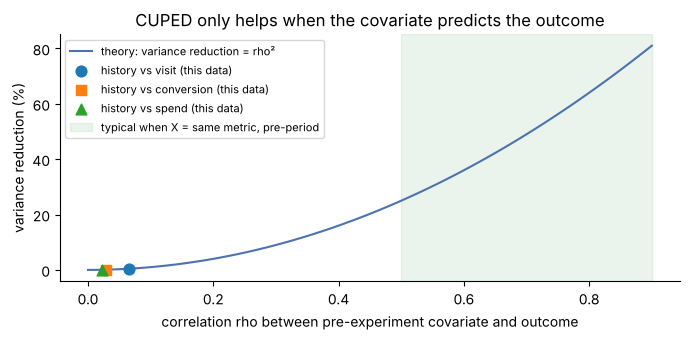

In [15]:
# Why so small? Variance reduction = rho^2. Plot the theory curve and where our covariates sit.
rhos = np.linspace(0, 0.9, 100)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(rhos, 100 * rhos ** 2, color="#4C72B0", label="theory: variance reduction = rho²")
for metric, marker in zip(METRICS, ["o", "s", "^"]):
    r = abs(np.corrcoef(df["history"], df[metric])[0, 1])
    ax.scatter(r, 100 * r ** 2, s=60, marker=marker, zorder=3, label=f"history vs {metric} (this data)")
ax.axvspan(0.5, 0.9, color="#55A868", alpha=0.12, label="typical when X = same metric, pre-period")
ax.set(xlabel="correlation rho between pre-experiment covariate and outcome",
       ylabel="variance reduction (%)", title="CUPED only helps when the covariate predicts the outcome")
ax.legend(fontsize=8)
save_fig("04_cuped_theory")

**Honest finding:** CUPED helps very little here. Past-year spend is only weakly correlated with whether a
customer responds in this two-week window (rho is around 0.02 to 0.07), so the variance drops by roughly
rho^2, i.e. well under 1% with one covariate and only a few % with all of them. The measured reductions
match the rho^2 formula, which confirms the method is implemented correctly.

In practice CUPED shines when the covariate is **the same metric measured for the same user before the
experiment** (e.g. last month's visits to predict this month's visits), where rho is often 0.5 to 0.8,
giving 25% to 64% less variance. This dataset does not record pre-period visits. **The lesson: CUPED's value
depends on having a strongly predictive pre-period metric, so check rho before relying on it.**

## 6. The danger of "peeking", and how to fix it
A common real-world mistake: check the p-value every day and stop as soon as it drops below 0.05. Each
check is another chance for random noise to cross the line, so the real false-positive rate ends up far
above 5%.

**Simulation:** take only the **control** customers (they all got no email, so there is truly no effect),
randomly split them into fake groups "A" and "B" (an **A/A test**), let them "arrive" in random order and
check the z-test after every 1,000 customers. Repeat 2,000 times and count how often we would have wrongly
declared a winner.

In [16]:
def z_path(y, labels, peek_idx):
    """z-statistics of a two-proportion test at each peek, for many simulated orderings at once.
    y, labels: arrays of shape (n_sims, n) in arrival order. labels: 1 = group A, 0 = group B."""
    a_n = np.cumsum(labels, axis=1)[:, peek_idx]
    b_n = np.cumsum(1 - labels, axis=1)[:, peek_idx]
    a_x = np.cumsum(y * labels, axis=1)[:, peek_idx]
    b_x = np.cumsum(y * (1 - labels), axis=1)[:, peek_idx]
    p_pool = (a_x + b_x) / (a_n + b_n)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / a_n + 1 / b_n))
    with np.errstate(divide="ignore", invalid="ignore"):
        z = (a_x / a_n - b_x / b_n) / se
    return np.nan_to_num(z)


def simulate_aa(y_ctrl, n_sims, peek_every, seed, batch=200):
    r = np.random.default_rng(seed)
    n = len(y_ctrl)
    peek_idx = np.arange(peek_every, n + 1, peek_every) - 1
    out = []
    for start in range(0, n_sims, batch):
        m = min(batch, n_sims - start)
        order = np.argsort(r.random((m, n)), axis=1)        # random arrival order per simulation
        y = y_ctrl[order].astype(np.int32)
        labels = r.integers(0, 2, size=(m, n), dtype=np.int32)  # random fake A/B labels
        out.append(z_path(y, labels, peek_idx))
    return np.vstack(out), (peek_idx + 1) / n


PEEK_EVERY = 1000
N_SIMS = 2000
y_ctrl_visit = ctrl["visit"].to_numpy()
Z_aa, info_frac = simulate_aa(y_ctrl_visit, N_SIMS, PEEK_EVERY, seed=1)
K = Z_aa.shape[1]
crit = stats.norm.ppf(0.975)

fpr_single = np.mean(np.abs(Z_aa[:, -1]) > crit)
fpr_by_peeks = [np.mean((np.abs(Z_aa[:, :k]) > crit).any(axis=1)) for k in range(1, K + 1)]
print(f"{K} peeks, {N_SIMS} simulated A/A tests")
print(f"False-positive rate, one look at the end : {fpr_single:.1%}  (should be about 5%)")
print(f"False-positive rate, stop at first p<0.05: {fpr_by_peeks[-1]:.1%}")
summary["peeking_n_peeks"] = int(K)
summary["fpr_single_look"] = float(fpr_single)
summary["fpr_naive_peeking"] = float(fpr_by_peeks[-1])

21 peeks, 2000 simulated A/A tests
False-positive rate, one look at the end : 5.5%  (should be about 5%)
False-positive rate, stop at first p<0.05: 23.8%


### The fix: sequential testing with an O'Brien-Fleming boundary
Instead of using the 1.96 threshold at every peek, use a threshold that is **strict early and relaxes
towards the end**:

$$\text{reject at peek } k \text{ if } |z_k| > \frac{c}{\sqrt{t_k}}$$

where t_k is the fraction of the sample seen so far. The constant c is chosen so that the chance of
*ever* crossing the boundary, when there is no effect, is exactly 5%. We find c by simulating pure-noise
random walks (the theoretical null), **not** from our data, and then check on fresh A/A simulations from
the real data that the false-positive rate is back to about 5%.

In [17]:
def calibrate_obf(info_frac, alpha=0.05, n_paths=200_000, seed=7):
    """Find c so that P(any |Z_k| > c / sqrt(t_k)) = alpha for a Brownian-motion null."""
    r = np.random.default_rng(seed)
    increments_var = np.diff(np.concatenate([[0.0], info_frac]))
    S = np.cumsum(r.standard_normal((n_paths, len(info_frac))) * np.sqrt(increments_var), axis=1)
    Z = S / np.sqrt(info_frac)
    return np.quantile(np.max(np.abs(Z) * np.sqrt(info_frac), axis=1), 1 - alpha)


c_obf = calibrate_obf(info_frac)
boundary = c_obf / np.sqrt(info_frac)
print(f"O'Brien-Fleming constant c = {c_obf:.3f}")
print(f"Boundary: |z| > {boundary[0]:.2f} at the first peek ... |z| > {boundary[-1]:.2f} at the last peek")

Z_aa_fresh, _ = simulate_aa(y_ctrl_visit, N_SIMS, PEEK_EVERY, seed=2)   # fresh simulations for validation
fpr_obf = np.mean((np.abs(Z_aa_fresh) > boundary).any(axis=1))
print(f"False-positive rate with sequential boundary: {fpr_obf:.1%}  (target 5%)")
summary["fpr_sequential_obf"] = float(fpr_obf)
summary["obf_c"] = float(c_obf)

O'Brien-Fleming constant c = 2.109
Boundary: |z| > 9.73 at the first peek ... |z| > 2.12 at the last peek
False-positive rate with sequential boundary: 4.9%  (target 5%)


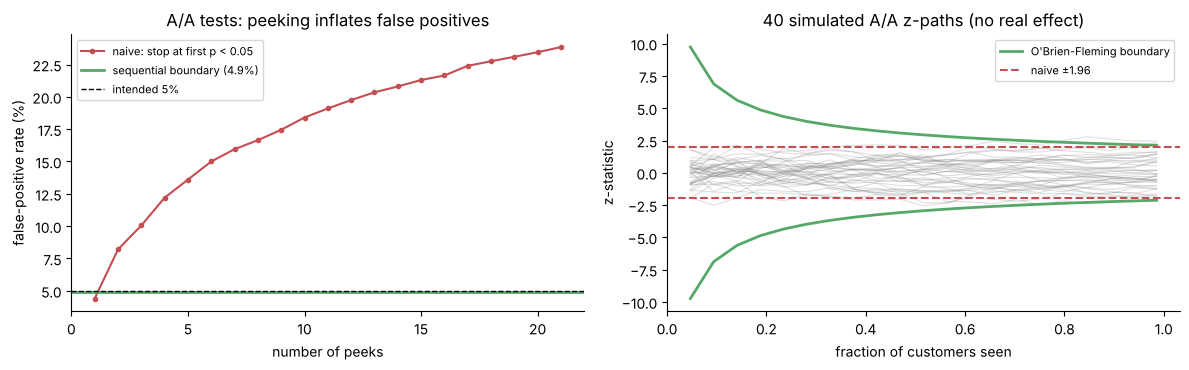

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(range(1, K + 1), 100 * np.array(fpr_by_peeks), marker="o", ms=3, color="#C44E52",
             label="naive: stop at first p < 0.05")
axes[0].axhline(100 * fpr_obf, color="#55A868", lw=2, label=f"sequential boundary ({fpr_obf:.1%})")
axes[0].axhline(5, color="black", ls="--", lw=1, label="intended 5%")
axes[0].set(xlabel="number of peeks", ylabel="false-positive rate (%)",
            title="A/A tests: peeking inflates false positives")
axes[0].set_xticks(range(0, K + 1, 5))
axes[0].legend(fontsize=8)
for path in Z_aa[:40]:
    axes[1].plot(info_frac, path, color="grey", alpha=0.25, lw=0.8)
axes[1].plot(info_frac, boundary, color="#55A868", lw=2, label="O'Brien-Fleming boundary")
axes[1].plot(info_frac, -boundary, color="#55A868", lw=2)
axes[1].axhline(crit, color="#C44E52", ls="--", label="naive ±1.96")
axes[1].axhline(-crit, color="#C44E52", ls="--")
axes[1].set(xlabel="fraction of customers seen", ylabel="z-statistic",
            title="40 simulated A/A z-paths (no real effect)")
axes[1].legend(fontsize=8, loc="upper right")
save_fig("05_peeking")

### Does the fix cost us anything when there *is* a real effect?
Now replay the **real** Womens E-Mail vs control experiment on `conversion` (the weakest of our real
effects, so the hardest to detect) in 500 random arrival orders. We compare the fixed one-look test with the
sequential test: how often each detects the effect, and how much data the sequential test needed before it
could stop.

In [19]:
def simulate_real(y_t, y_c, n_sims, peek_every, seed, batch=100):
    r = np.random.default_rng(seed)
    y_all = np.concatenate([y_t, y_c]).astype(np.int32)
    lab_all = np.concatenate([np.ones(len(y_t)), np.zeros(len(y_c))]).astype(np.int32)
    n = len(y_all)
    peek_idx = np.arange(peek_every, n + 1, peek_every) - 1
    out = []
    for start in range(0, n_sims, batch):
        m = min(batch, n_sims - start)
        order = np.argsort(r.random((m, n)), axis=1)
        out.append(z_path(y_all[order], lab_all[order], peek_idx))
    return np.vstack(out), (peek_idx + 1) / n


trt_w = df[df["segment"] == WOMENS]
Z_real, frac_real = simulate_real(trt_w["conversion"].to_numpy(), ctrl["conversion"].to_numpy(),
                                  500, 2 * PEEK_EVERY, seed=3)
bound_real = calibrate_obf(frac_real) / np.sqrt(frac_real)
crossed = np.abs(Z_real) > bound_real
detect_seq = crossed.any(axis=1).mean()
detect_fixed = (np.abs(Z_real[:, -1]) > crit).mean()
stop_frac = np.where(crossed.any(axis=1), frac_real[np.argmax(crossed, axis=1)], 1.0)
print(f"Detection rate, one look at the end : {detect_fixed:.1%}")
print(f"Detection rate, sequential boundary : {detect_seq:.1%}")
print(f"Average share of data needed by the sequential test: {stop_frac.mean():.0%}")
summary["seq_detect_rate"] = float(detect_seq)
summary["fixed_detect_rate"] = float(detect_fixed)
summary["seq_avg_data_used"] = float(stop_frac.mean())

Detection rate, one look at the end : 100.0%
Detection rate, sequential boundary : 100.0%
Average share of data needed by the sequential test: 57%


**Reading it:** naive peeking multiplies the false-positive rate several times over. The sequential boundary
brings it back to about 5%, while still detecting a real effect about as often as a single look at the end,
and often letting the test stop early. That is why experimentation platforms use sequential methods
rather than forbidding people from looking.

## 7. Who responds? Segments and targeting
### 7a. Segment analysis
The average effect hides differences between customers. We split by buyer type (what they bought before),
new vs returning, channel and area, and measure the visit lift of each email within each segment.

**Caution:** slicing into many segments means many tests (here 22), so we apply Holm again. Segment findings
found after the fact should be treated as hypotheses to confirm in a new experiment.

In [20]:
df["buyer_type"] = np.select([(df.mens == 1) & (df.womens == 1), df.mens == 1],
                             ["Bought both", "Bought mens only"], "Bought womens only")
df["customer_type"] = np.where(df["newbie"] == 1, "New (last 12 months)", "Returning")
seg_vars = ["buyer_type", "customer_type", "channel", "zip_code"]

seg_rows = []
for var in seg_vars:
    for level in sorted(df[var].unique()):
        sub = df[df[var] == level]
        c = sub[sub["segment"] == CONTROL]
        for email in EMAILS:
            t = sub[sub["segment"] == email]
            r = two_prop_ztest(t["visit"].sum(), len(t), c["visit"].sum(), len(c))
            seg_rows.append({"variable": var, "level": level, "email": email,
                             "n_treat": len(t), "n_ctrl": len(c), **r})
segments = pd.DataFrame(seg_rows)
segments["p_holm"] = holm_adjust(segments["p_value"])
segments["lift_pp"] = 100 * segments["diff"]
segments[["variable", "level", "email", "control", "treatment", "lift_pp", "p_value", "p_holm"]].round(4)

,variable,level,email,control,treatment,lift_pp,p_value,p_holm
0,buyer_type,Bought both,Mens E-Mail,0.1805,0.3150,13.4444,0.0000,0.0000
1,buyer_type,Bought both,Womens E-Mail,0.1805,0.2517,7.1103,0.0000,0.0000
2,buyer_type,Bought mens only,Mens E-Mail,0.0998,0.1690,6.9155,0.0000,0.0000
3,buyer_type,Bought mens only,Womens E-Mail,0.0998,0.1109,1.1078,0.0123,0.0123
4,buyer_type,Bought womens only,Mens E-Mail,0.0958,0.1664,7.0580,0.0000,0.0000
5,buyer_type,Bought womens only,Womens E-Mail,0.0958,0.1698,7.3985,0.0000,0.0000
6,customer_type,New (last 12 months),Mens E-Mail,0.0788,0.1541,7.5305,0.0000,0.0000
7,customer_type,New (last 12 months),Womens E-Mail,0.0788,0.1292,5.0417,0.0000,0.0000
8,customer_type,Returning,Mens E-Mail,0.1337,0.2116,7.7833,0.0000,0.0000
9,customer_type,Returning,Womens E-Mail,0.1337,0.1739,4.0123,0.0000,0.0000


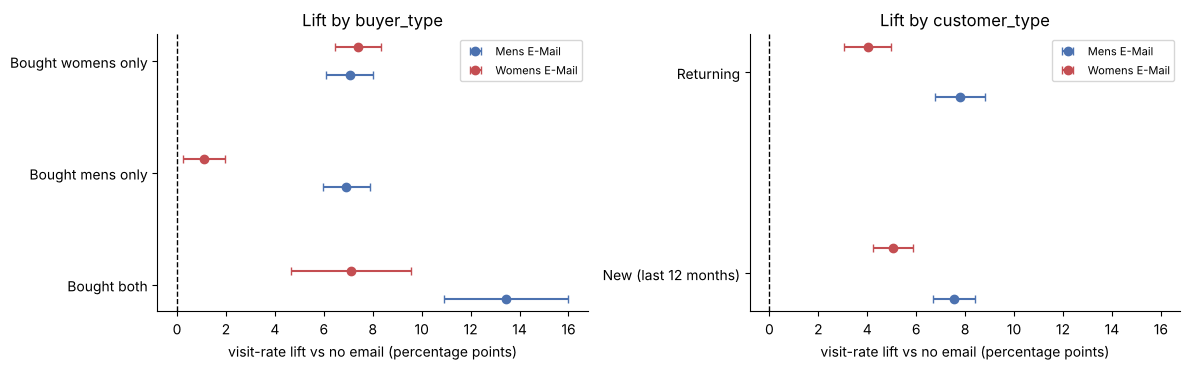

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, var in zip(axes, ["buyer_type", "customer_type"]):
    sub = segments[segments["variable"] == var].reset_index(drop=True)
    levels = sorted(sub["level"].unique())
    for j, (email, color) in enumerate(zip(EMAILS, ["#4C72B0", "#C44E52"])):
        s = sub[sub["email"] == email].set_index("level").loc[levels]
        ypos = np.arange(len(levels)) + (j - 0.5) * 0.25
        ax.errorbar(100 * s["diff"], ypos, xerr=[100 * (s["diff"] - s["ci_low"]), 100 * (s["ci_high"] - s["diff"])],
                    fmt="o", capsize=3, color=color, label=email)
    ax.set_yticks(range(len(levels)), levels)
    ax.axvline(0, color="black", lw=1, ls="--")
    ax.set(xlabel="visit-rate lift vs no email (percentage points)", title=f"Lift by {var}")
    ax.legend(fontsize=8)
save_fig("06_segments")

In [22]:
# Is the difference BETWEEN two segments real? That needs its own test (difference of two differences).
def diff_of_diffs(email, level_a, level_b, var="buyer_type"):
    a = segments[(segments.variable == var) & (segments.level == level_a) & (segments.email == email)].iloc[0]
    b = segments[(segments.variable == var) & (segments.level == level_b) & (segments.email == email)].iloc[0]
    se = lambda r: (r["ci_high"] - r["ci_low"]) / (2 * stats.norm.ppf(0.975))
    z = (a["diff"] - b["diff"]) / np.sqrt(se(a) ** 2 + se(b) ** 2)
    return a["diff"] - b["diff"], 2 * stats.norm.sf(abs(z))

for email in EMAILS:
    d, p = diff_of_diffs(email, "Bought mens only", "Bought womens only")
    print(f"{email}: lift for mens-only buyers minus lift for womens-only buyers = {100*d:+.2f} pp (p = {p:.2g})")
    summary[f"interaction|{email}"] = {"diff_pp": float(100 * d), "p_value": float(p)}

seg_bt = segments[segments.variable == "buyer_type"]
summary["segment_lifts_pp"] = {f"{r.email}|{r.level}": round(float(r.lift_pp), 2) for r in seg_bt.itertuples()}
summary["segments_significant_after_holm"] = int((segments["p_holm"] < 0.05).sum())
summary["segments_tested"] = int(len(segments))

Mens E-Mail: lift for mens-only buyers minus lift for womens-only buyers = -0.14 pp (p = 0.84)
Womens E-Mail: lift for mens-only buyers minus lift for womens-only buyers = -6.29 pp (p = 1.2e-21)


**Reading it (the most useful business finding):**
- The **Mens E-Mail** lifts visits by about 7 percentage points for *every* buyer type, and by about 13 pp for
  customers who bought both kinds of products before. Its effect does not depend on what the customer bought
  before (difference between mens-only and womens-only buyers: p = 0.84).
- The **Womens E-Mail** works well on womens-only buyers (about 7 pp) but **barely moves mens-only buyers**
  (about 1 pp). That gap of about 6 pp is far too large to be chance (p < 1e-20).
- So "Mens E-Mail to everyone" is the safer default, and the Womens E-Mail only makes sense for customers
  with a women's purchase history. This kind of insight is invisible in the overall averages.

### 7b. Uplift model: who visits *because of* the email?
A normal model predicts "who will visit". That is the wrong question: some customers visit anyway.
We want the **uplift**: P(visit | gets email) - P(visit | no email).

**T-learner (two-model approach):** train one classifier per group on pre-experiment features only:
- model_control predicts P(visit) without an email
- model_mens and model_womens predict P(visit) with each email

Predicted uplift of an email = its model's prediction - the control model's prediction. Each customer's best
email is the one with the larger predicted uplift.

We train on 70% of customers and evaluate on the other 30%, which the models never saw. Because the test
customers were *randomly* assigned, we can check the predictions honestly: rank test customers by predicted
uplift and compare the observed visit rate of emailed vs non-emailed customers within each group.

In [23]:
feature_cols = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]
X_all = pd.get_dummies(df[feature_cols], drop_first=True).astype(float)
train_idx, test_idx = train_test_split(df.index, test_size=0.3, random_state=SEED, stratify=df["segment"])

models = {}
for arm in [CONTROL, MENS, WOMENS]:
    rows_arm = train_idx[df.loc[train_idx, "segment"] == arm]
    m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                       min_samples_leaf=100, l2_regularization=1.0, random_state=SEED)
    m.fit(X_all.loc[rows_arm], df.loc[rows_arm, "visit"])
    models[arm] = m

test = df.loc[test_idx].copy()
Xt = X_all.loc[test_idx]
p_ctrl = models[CONTROL].predict_proba(Xt)[:, 1]
test["uplift_mens"] = models[MENS].predict_proba(Xt)[:, 1] - p_ctrl
test["uplift_womens"] = models[WOMENS].predict_proba(Xt)[:, 1] - p_ctrl
test["best_email"] = np.where(test["uplift_mens"] >= test["uplift_womens"], MENS, WOMENS)
test["best_uplift"] = test[["uplift_mens", "uplift_womens"]].max(axis=1)
print("Test customers:", len(test))
print(test["best_email"].value_counts(normalize=True).round(3).to_string())

Test customers: 19200
best_email
Mens E-Mail      0.769
Womens E-Mail    0.231


Mens E-Mail: top-3 deciles avg lift 9.6 pp vs bottom-3 deciles 7.2 pp
Womens E-Mail: top-3 deciles avg lift 8.1 pp vs bottom-3 deciles 1.7 pp


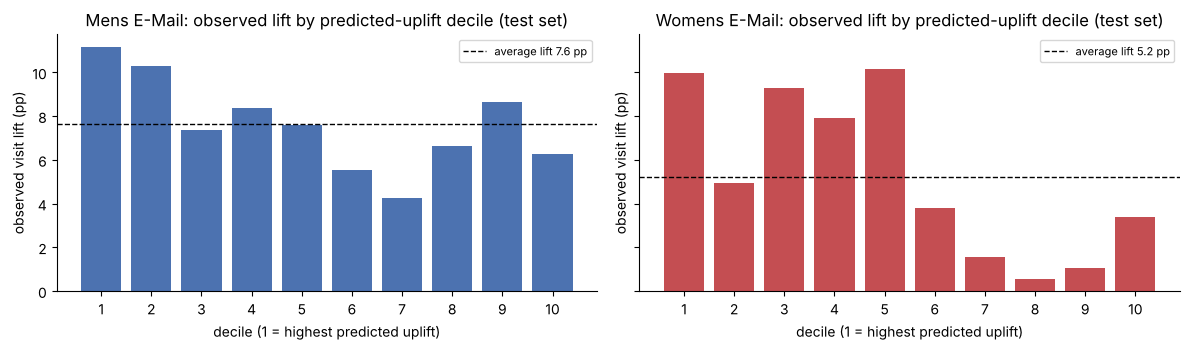

In [24]:
def observed_lift_by_decile(data, email, score_col, n_bins=10):
    sub = data[data["segment"].isin([email, CONTROL])].copy()
    sub["decile"] = pd.qcut(sub[score_col].rank(method="first", ascending=False), n_bins, labels=False) + 1
    g = sub.groupby(["decile", "segment"])["visit"].mean().unstack()
    return 100 * (g[email] - g[CONTROL])


fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
decile_lifts = {}
for ax, email, col, color in zip(axes, EMAILS, ["uplift_mens", "uplift_womens"], ["#4C72B0", "#C44E52"]):
    lifts = observed_lift_by_decile(test, email, col)
    decile_lifts[email] = lifts
    ax.bar(lifts.index, lifts.values, color=color)
    overall = 100 * (test.loc[test.segment == email, "visit"].mean() - test.loc[test.segment == CONTROL, "visit"].mean())
    ax.axhline(overall, color="black", ls="--", lw=1, label=f"average lift {overall:.1f} pp")
    ax.set(title=f"{email}: observed lift by predicted-uplift decile (test set)",
           xlabel="decile (1 = highest predicted uplift)", ylabel="observed visit lift (pp)")
    ax.set_xticks(range(1, 11)); ax.legend(fontsize=8)
save_fig("07_uplift_deciles")

for email in EMAILS:
    l = decile_lifts[email]
    print(f"{email}: top-3 deciles avg lift {l.loc[1:3].mean():.1f} pp vs bottom-3 deciles {l.loc[8:10].mean():.1f} pp")
    summary[f"uplift_top3_vs_bottom3|{email}"] = [round(float(l.loc[1:3].mean()), 2),
                                                  round(float(l.loc[8:10].mean()), 2)]

**Reading it:** for the Womens E-Mail the model separates customers well: the top predicted deciles show a
much larger observed lift than the bottom ones, mostly because it learns the buyer-type pattern from 7a.
For the Mens E-Mail the ranking is weaker and noisier, which makes sense: that email works for almost
everyone, so there is less difference between customers to find. Each decile holds only about 1,300
customers (emailed and control together), so individual bars are noisy; look at the overall slope, not single bars.

### 7c. The challenge question: if we can email only 10,000 customers, who?
10,000 of 64,000 customers is 15.6%. Policy: take the 15.6% of test customers with the highest predicted
uplift and send each one their best email. To estimate how well this would have worked, we use the random
assignment: inside the chosen group, compare customers who *happened* to receive their recommended email with
those who received no email. We compare that with emailing 10,000 random customers the overall better email.

In [25]:
TARGET_N, TOTAL_N = 10_000, len(df)
top = test.nlargest(int(round(len(test) * TARGET_N / TOTAL_N)), "best_uplift")
got_best = top[top["segment"] == top["best_email"]]
got_none = top[top["segment"] == CONTROL]

lift_top = two_prop_ztest(got_best["visit"].sum(), len(got_best), got_none["visit"].sum(), len(got_none))
spend_boot = bootstrap_diff_in_means(got_best["spend"].to_numpy(), got_none["spend"].to_numpy(), n_boot=5000)
lift_random = effects[(effects.email == MENS) & (effects.metric == "visit")].iloc[0]
spend_random = effects[(effects.email == MENS) & (effects.metric == "spend")].iloc[0]

print(f"Targeted group in test set: {len(top)} customers "
      f"({len(got_best)} got their recommended email, {len(got_none)} got none)")
print(f"\nVisit lift, targeted top 15.6%     : {100*lift_top['diff']:.1f} pp "
      f"(95% CI {100*lift_top['ci_low']:.1f} to {100*lift_top['ci_high']:.1f})")
print(f"Visit lift, random customers (Mens): {100*lift_random['diff']:.1f} pp")
print(f"=> extra visits per 10,000 emails: targeted ~{TARGET_N*lift_top['diff']:.0f} "
      f"vs random ~{TARGET_N*lift_random['diff']:.0f}")
print(f"\nSpend lift per customer, targeted: ${spend_boot.mean():.2f} "
      f"(95% CI ${np.percentile(spend_boot, 2.5):.2f} to ${np.percentile(spend_boot, 97.5):.2f})")
print(f"Spend lift per customer, random  : ${spend_random['diff']:.2f}")

summary["top10k"] = {
    "test_group_size": int(len(top)), "n_got_best": int(len(got_best)), "n_got_none": int(len(got_none)),
    "visit_lift_pp": float(100 * lift_top["diff"]), "visit_ci_pp": [float(100 * lift_top["ci_low"]), float(100 * lift_top["ci_high"])],
    "random_visit_lift_pp": float(100 * lift_random["diff"]),
    "extra_visits_per_10k_targeted": float(TARGET_N * lift_top["diff"]),
    "extra_visits_per_10k_random": float(TARGET_N * lift_random["diff"]),
    "spend_lift_targeted": float(spend_boot.mean()),
    "spend_ci_targeted": [float(np.percentile(spend_boot, 2.5)), float(np.percentile(spend_boot, 97.5))],
    "spend_lift_random": float(spend_random["diff"]),
    "best_email_share_mens": float((top["best_email"] == MENS).mean()),
}

Targeted group in test set: 3000 customers (969 got their recommended email, 1000 got none)

Visit lift, targeted top 15.6%     : 12.1 pp (95% CI 8.6 to 15.5)
Visit lift, random customers (Mens): 7.7 pp
=> extra visits per 10,000 emails: targeted ~1208 vs random ~766

Spend lift per customer, targeted: $1.30 (95% CI $0.04 to $2.75)
Spend lift per customer, random  : $0.77


In [26]:
# Who are these customers? Compare the targeted group with everyone.
profile = pd.DataFrame({
    "targeted top 15.6%": top[["history", "recency", "mens", "womens", "newbie"]].mean(),
    "all customers": df[["history", "recency", "mens", "womens", "newbie"]].mean(),
}).round(2)
profile.loc["channel = Web"] = [(top.channel == "Web").mean().round(2), (df.channel == "Web").mean().round(2)]
profile.loc["recommended Mens E-Mail"] = [(top.best_email == MENS).mean().round(2), np.nan]
profile

,targeted top 15.6%,all customers
history,389.12,242.09
recency,5.55,5.76
mens,0.70,0.55
womens,0.68,0.55
newbie,0.44,0.50
channel = Web,0.46,0.44
recommended Mens E-Mail,0.76,NaN


## 8. Summary and recommendation
The final cell prints the key numbers and saves them to `results/summary.json`. The README turns these into a
short decision memo.

**Limitations**
- The data is from 2008, from one retailer, over a single two-week window: long-term effects (e.g. people
  unsubscribing) are not measured.
- Spend is driven by fewer than 1% of customers, so spend estimates are noisy, especially inside segments.
- Segment and uplift findings are exploratory: the next step is to confirm the targeting rule in a new
  randomized test (targeted vs untargeted).
- The top-10,000 estimate rests on about 2,000 test customers (those who got their recommended email or no
  email), so its confidence interval is wide, especially for spend.

In [27]:
with open(RESULTS_DIR / "summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "srm_p_value": 0.904,
  "max_abs_smd": 0.0086,
  "Mens E-Mail|visit": {
    "control": 0.10616727682343002,
    "treatment": 0.18275684047496127,
    "diff": 0.07658956365153125,
    "ci_low": 0.06995350121810838,
    "ci_high": 0.08322562608495411,
    "relative_lift_pct": 72.1404616781399,
    "p_value": 5.685165482802317e-112,
    "p_holm": 3.41109928968139e-111
  },
  "Mens E-Mail|conversion": {
    "control": 0.005726086548390125,
    "treatment": 0.01253109306800582,
    "diff": 0.006805006519615695,
    "ci_low": 0.005000171380452313,
    "ci_high": 0.008609841658779076,
    "relative_lift_pct": 118.84218762863279,
    "p_value": 1.5232235005955427e-13,
    "p_holm": 6.092894002382171e-13
  },
  "Mens E-Mail|spend": {
    "control": 0.6527893551112361,
    "treatment": 1.422616511005773,
    "diff": 0.7698271558945368,
    "ci_low": 0.4855973544572549,
    "ci_high": 1.0629855905306205,
    "relative_lift_pct": 117.92887703620063,
    "p_value": 1.163814968225482e-07,
    "p